Displaying: Combined Over (All 6 Balls in 1 Frame)...


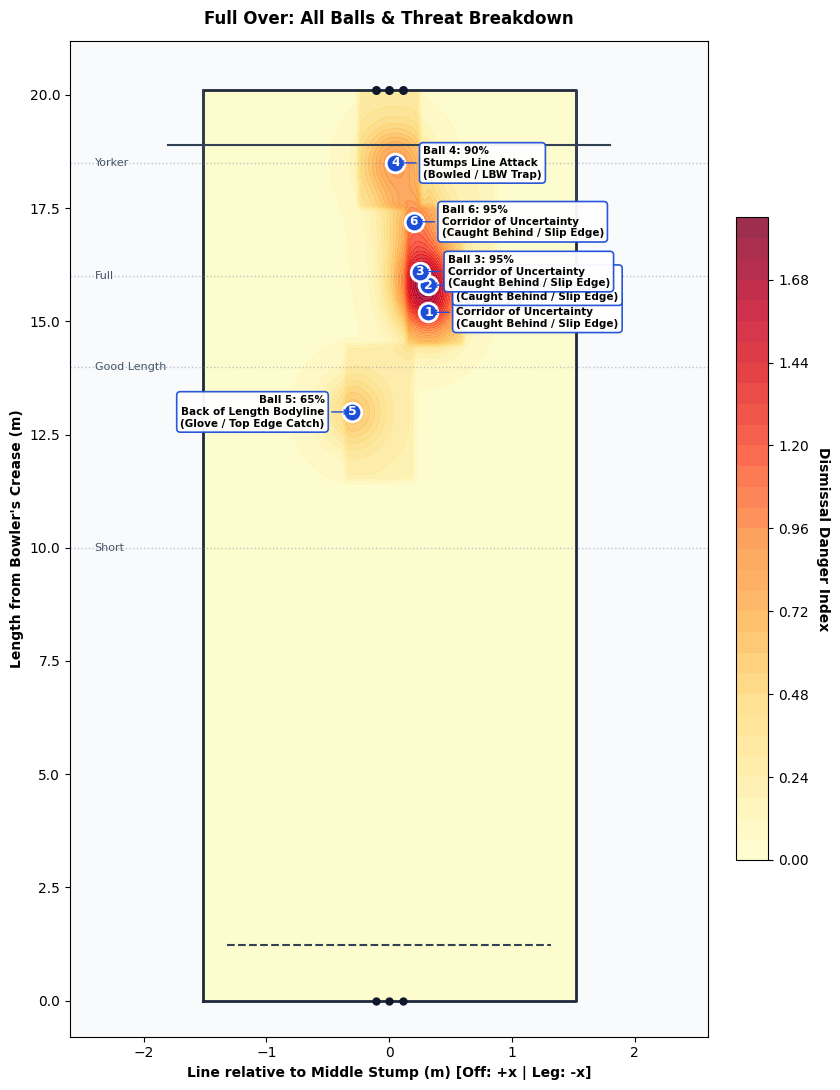

Displaying: Single Delivery Pitch for Ball 1...


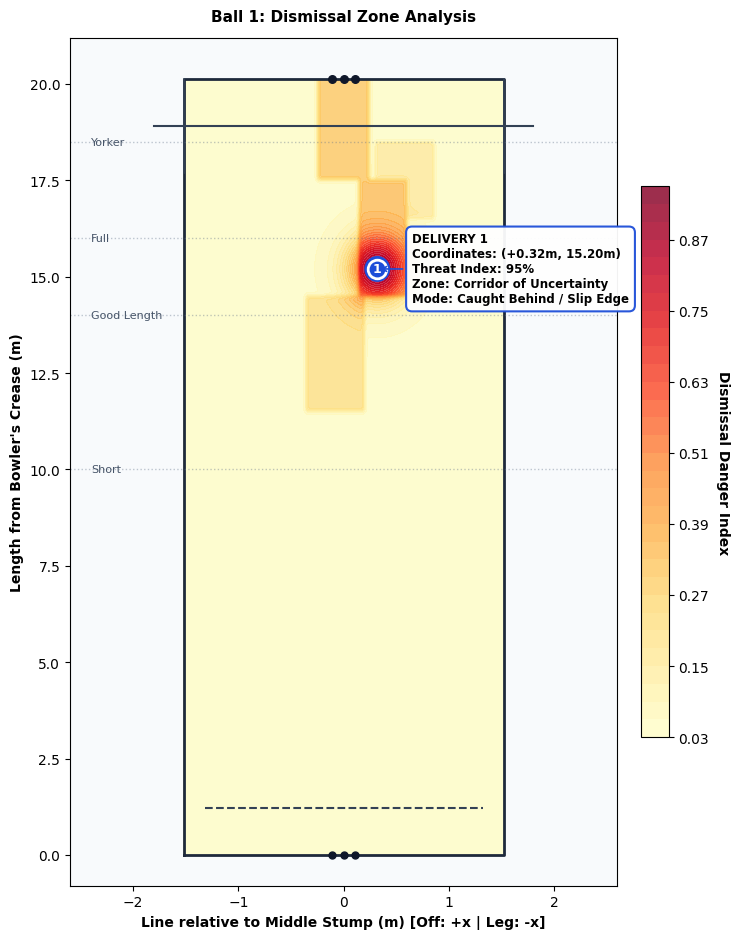

Displaying: Single Delivery Pitch for Ball 2...


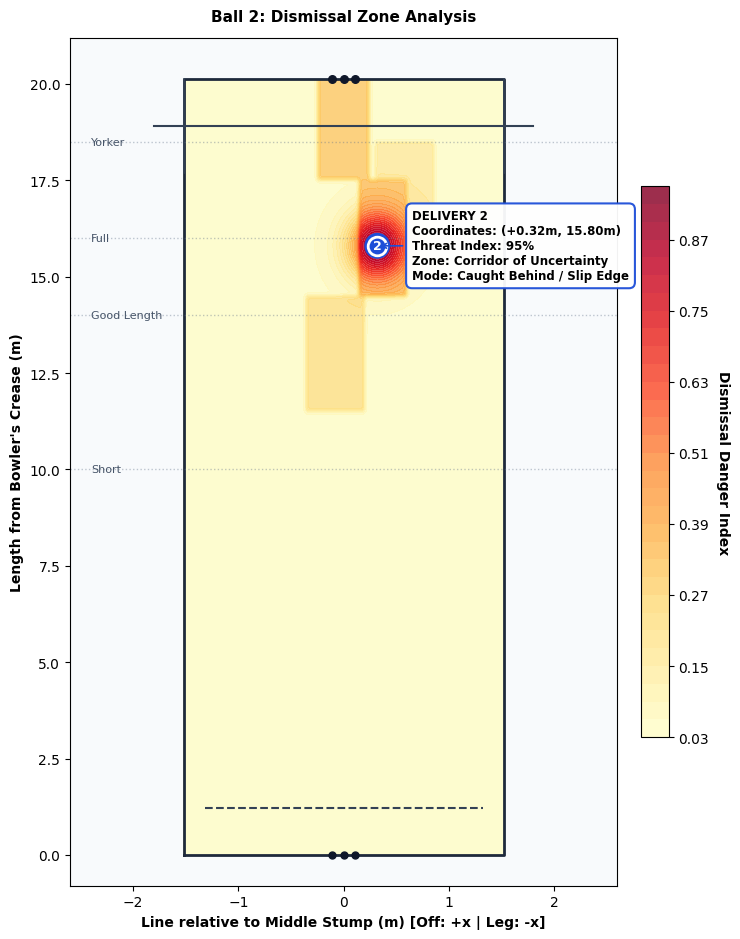

Displaying: Single Delivery Pitch for Ball 3...


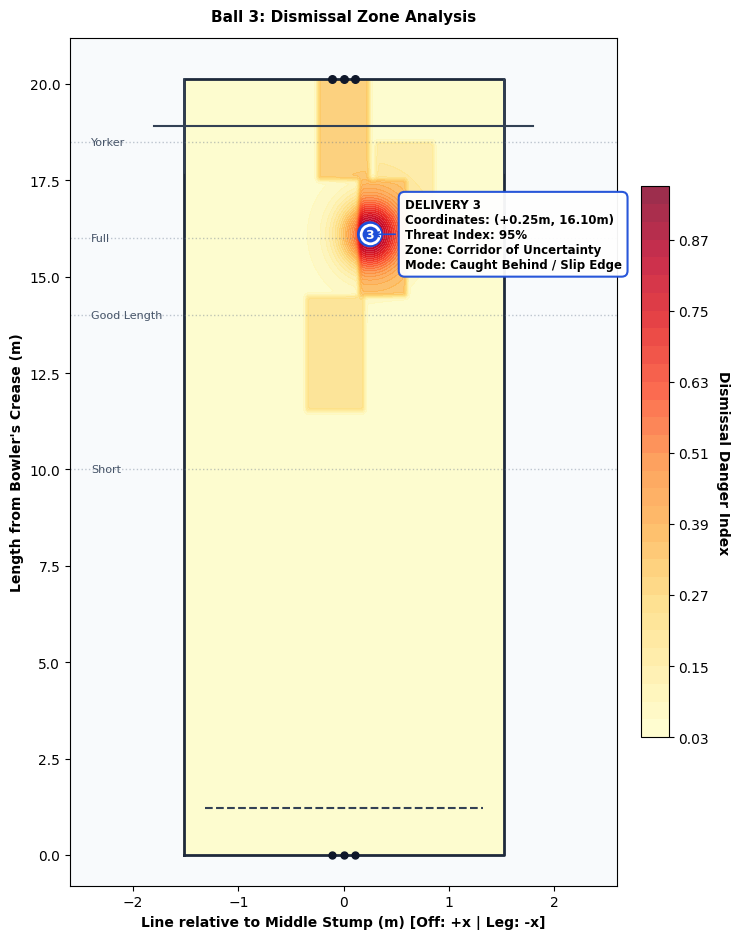

Displaying: Single Delivery Pitch for Ball 4...


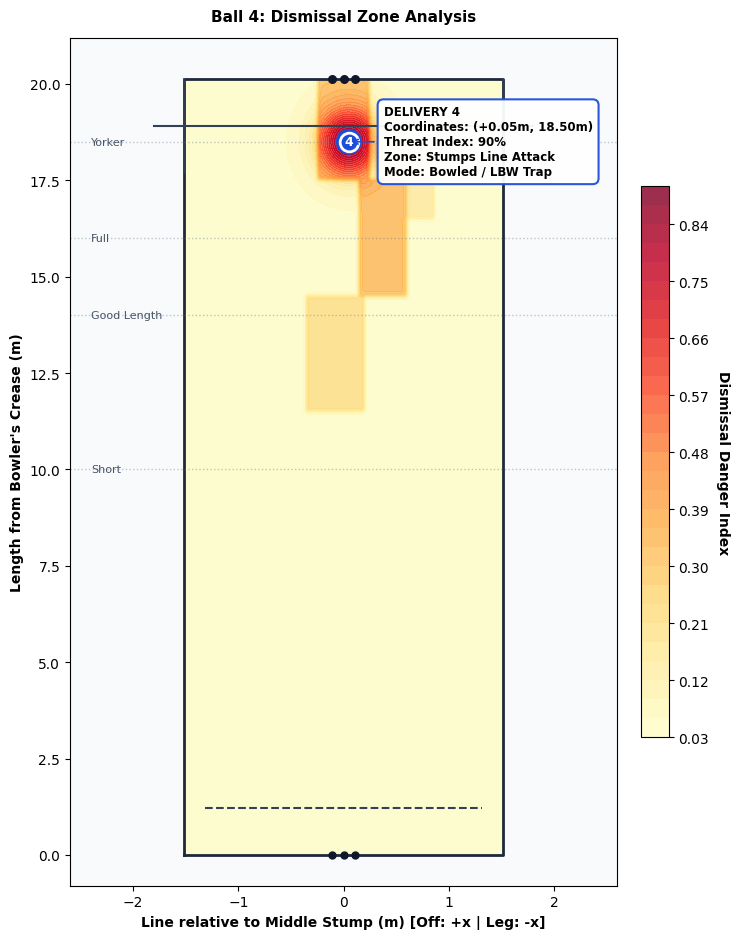

Displaying: Single Delivery Pitch for Ball 5...


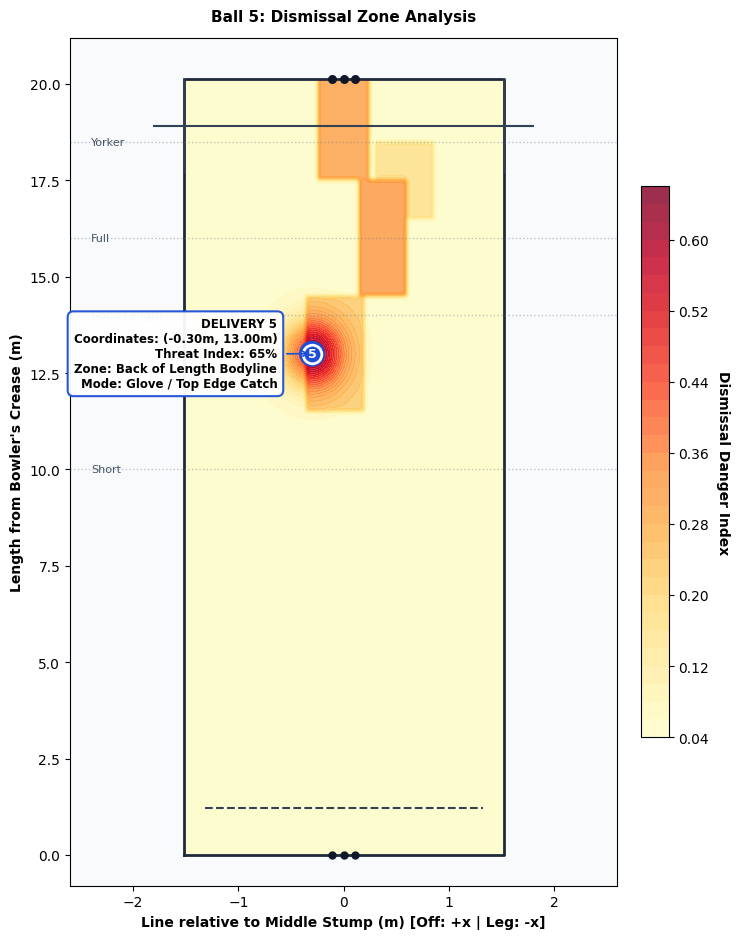

Displaying: Single Delivery Pitch for Ball 6...


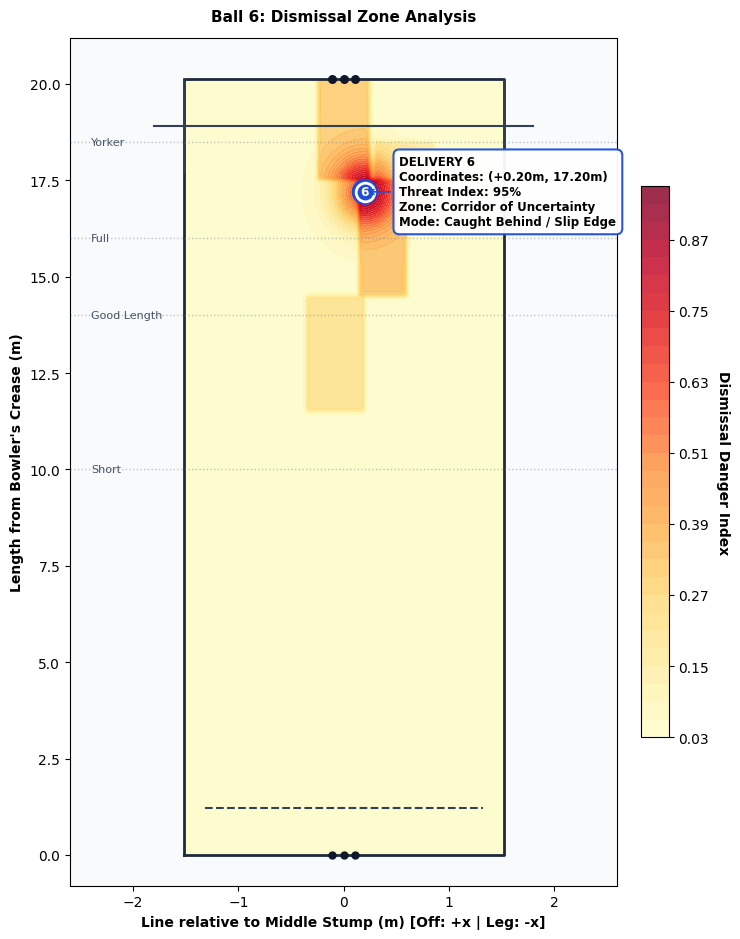

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter

# Ensure interactive plots display inline if running inside a notebook
try:
    from IPython import get_ipython
    if get_ipython() is not None:
        get_ipython().run_line_magic('matplotlib', 'inline')
except Exception:
    pass

# ======================================================================
# 1. INPUT DETECTIONS
# Line: +x (Off-side RHB), -x (Leg-side) | Length: 0m (Bowler) -> 20.12m (Stumps)
# ======================================================================
detected_over_snippet = [
    {"ball": 1, "pitch_x": 0.32, "pitch_y": 15.20},  # Good length outside off
    {"ball": 2, "pitch_x": 0.32, "pitch_y": 15.80},  # Edge zone
    {"ball": 3, "pitch_x": 0.25, "pitch_y": 16.10},  # Good length on off-stump
    {"ball": 4, "pitch_x": 0.05, "pitch_y": 18.50},  # Yorker on stumps
    {"ball": 5, "pitch_x": -0.30, "pitch_y": 13.00}, # Back of a length leg-side
    {"ball": 6, "pitch_x": 0.20, "pitch_y": 17.20}   # Full on stumps
]

# ======================================================================
# 2. DISMISSAL THREAT & ZONE DEFINITIONS
# ======================================================================
ZONES = [
    {
        "name": "Corridor of Uncertainty",
        "detail": "Caught Behind / Slip Edge",
        "threat": 0.95,
        "x_range": (0.15, 0.60),
        "y_range": (14.5, 17.5)
    },
    {
        "name": "Stumps Line Attack",
        "detail": "Bowled / LBW Trap",
        "threat": 0.90,
        "x_range": (-0.25, 0.25),
        "y_range": (17.5, 20.12)
    },
    {
        "name": "Back of Length Bodyline",
        "detail": "Glove / Top Edge Catch",
        "threat": 0.65,
        "x_range": (-0.35, 0.20),
        "y_range": (11.5, 14.5)
    },
    {
        "name": "Full Driving Trap",
        "detail": "Drive Edge / Cover Catch",
        "threat": 0.50,
        "x_range": (0.30, 0.85),
        "y_range": (16.5, 18.5)
    }
]

def classify_zone(x, y):
    for z in ZONES:
        if (z["x_range"][0] <= x <= z["x_range"][1]) and (z["y_range"][0] <= y <= z["y_range"][1]):
            return z["threat"], z["name"], z["detail"]
    return 0.15, "Non-Threat Zone", "Scoring / Defensive Area"

def build_risk_surface(xx, yy):
    conditions = [
        (yy >= z["y_range"][0]) & (yy <= z["y_range"][1]) &
        (xx >= z["x_range"][0]) & (xx <= z["x_range"][1])
        for z in ZONES
    ]
    choices = [z["threat"] for z in ZONES]
    return np.select(conditions, choices, default=0.15)

def draw_pitch_markings(ax):
    # Boundary (-1.52m to +1.52m width, 0m to 20.12m length)
    ax.plot([-1.52, 1.52, 1.52, -1.52, -1.52], [0, 0, 20.12, 20.12, 0], color="#1e293b", lw=2)

    # Creases
    ax.plot([-1.32, 1.32], [1.22, 1.22], color="#334155", lw=1.5, linestyle="--")   # Bowler crease
    ax.plot([-1.80, 1.80], [18.90, 18.90], color="#334155", lw=1.5)                 # Popping crease
    ax.plot([-1.52, -1.52], [17.68, 20.12], color="#334155", lw=1.2)                # Return crease L
    ax.plot([1.52, 1.52], [17.68, 20.12], color="#334155", lw=1.2)                  # Return crease R

    # Stumps
    ax.scatter([-0.11, 0, 0.11], [0, 0, 0], color="#0f172a", s=25, zorder=6)
    ax.scatter([-0.11, 0, 0.11], [20.12, 20.12, 20.12], color="#0f172a", s=30, zorder=6)

    # Length markers
    lengths = [(18.5, "Yorker"), (16.0, "Full"), (14.0, "Good Length"), (10.0, "Short")]
    for y_pos, label in lengths:
        ax.axhline(y=y_pos, color="#64748b", linestyle=":", alpha=0.4, lw=1)
        ax.text(-2.4, y_pos, label, fontsize=8, color="#475569", va="center")

    ax.set_facecolor("#f8fafc")
    ax.set_xlabel("Line relative to Middle Stump (m) [Off: +x | Leg: -x]", fontweight="bold")
    ax.set_ylabel("Length from Bowler's Crease (m)", fontweight="bold")

# ======================================================================
# 3. COMBINED ALL-BALLS PITCH RENDERER
# ======================================================================
def show_all_balls_combined_pitch(balls_data, output_file=None):
    x_grid = np.linspace(-1.52, 1.52, 250)
    y_grid = np.linspace(0.0, 20.12, 500)
    xx, yy = np.meshgrid(x_grid, y_grid)

    base_surface = build_risk_surface(xx, yy)
    ball_field = np.zeros_like(xx)
    sigma_x, sigma_y = 0.18, 0.55

    for b in balls_data:
        t_val, _, _ = classify_zone(b["pitch_x"], b["pitch_y"])
        kernel = np.exp(-(((xx - b["pitch_x"]) ** 2) / (2 * sigma_x ** 2) +
                          ((yy - b["pitch_y"]) ** 2) / (2 * sigma_y ** 2)))
        ball_field += kernel * t_val

    composite = (0.35 * base_surface) + (0.65 * ball_field)
    composite = gaussian_filter(composite, sigma=1.2)

    fig, ax = plt.subplots(figsize=(8.5, 11))
    heat = ax.contourf(xx, yy, composite, levels=30, cmap="YlOrRd", alpha=0.82)
    cbar = fig.colorbar(heat, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label("Dismissal Danger Index", rotation=270, labelpad=15, fontweight="bold")

    draw_pitch_markings(ax)

    # Plot all deliveries in the single frame
    for b in balls_data:
        bx, by, b_num = b["pitch_x"], b["pitch_y"], b["ball"]
        threat, zone_name, zone_detail = classify_zone(bx, by)

        ax.scatter(bx, by, color="#1d4ed8", edgecolors="white", s=180, linewidth=2, zorder=7)
        ax.text(bx, by, str(b_num), color="white", fontsize=9, fontweight="bold", ha="center", va="center", zorder=8)

        x_offset = 20 if bx >= 0 else -20
        ha_align = "left" if bx >= 0 else "right"

        ax.annotate(
            f"Ball {b_num}: {threat*100:.0f}%\n{zone_name}\n({zone_detail})",
            (bx, by),
            xytext=(x_offset, 0),
            textcoords="offset points",
            fontsize=7.5,
            fontweight="bold",
            ha=ha_align,
            va="center",
            bbox=dict(boxstyle="round,pad=0.35", fc="#ffffff", ec="#1d4ed8", lw=1.2, alpha=0.95),
            arrowprops=dict(arrowstyle="->", color="#1d4ed8", lw=1),
            zorder=9
        )

    ax.set_xlim(-2.6, 2.6)
    ax.set_ylim(-0.8, 21.2)
    ax.set_title("Full Over: All Balls & Threat Breakdown", fontsize=12, fontweight="bold", pad=12)

    plt.tight_layout()
    if output_file:
        plt.savefig(output_file, dpi=200)
    plt.show()  # Displays image directly on screen/cell

# ======================================================================
# 4. INDIVIDUAL BALL PITCH RENDERER
# ======================================================================
def show_single_ball_pitch(ball_data, output_file=None):
    bx, by, b_num = ball_data["pitch_x"], ball_data["pitch_y"], ball_data["ball"]
    threat, zone_name, zone_detail = classify_zone(bx, by)

    x_grid = np.linspace(-1.52, 1.52, 250)
    y_grid = np.linspace(0.0, 20.12, 500)
    xx, yy = np.meshgrid(x_grid, y_grid)

    base_surface = build_risk_surface(xx, yy)

    sigma_x, sigma_y = 0.20, 0.60
    ball_field = np.exp(-(((xx - bx) ** 2) / (2 * sigma_x ** 2) +
                          ((yy - by) ** 2) / (2 * sigma_y ** 2))) * threat

    composite = (0.35 * base_surface) + (0.65 * ball_field)
    composite = gaussian_filter(composite, sigma=1.2)

    fig, ax = plt.subplots(figsize=(7.5, 9.5))
    heat = ax.contourf(xx, yy, composite, levels=30, cmap="YlOrRd", alpha=0.82)
    cbar = fig.colorbar(heat, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label("Dismissal Danger Index", rotation=270, labelpad=15, fontweight="bold")

    draw_pitch_markings(ax)

    # Highlight ring and ball center
    ax.scatter(bx, by, s=260, facecolors="none", edgecolors="#1d4ed8", linewidth=2.5, zorder=6)
    ax.scatter(bx, by, color="#1d4ed8", edgecolors="white", s=180, linewidth=2, zorder=7)
    ax.text(bx, by, str(b_num), color="white", fontsize=9, fontweight="bold", ha="center", va="center", zorder=8)

    callout_text = (
        f"DELIVERY {b_num}\n"
        f"Coordinates: ({bx:+.2f}m, {by:.2f}m)\n"
        f"Threat Index: {threat*100:.0f}%\n"
        f"Zone: {zone_name}\n"
        f"Mode: {zone_detail}"
    )
    x_offset = 25 if bx >= 0 else -25
    ha_align = "left" if bx >= 0 else "right"

    ax.annotate(
        callout_text,
        (bx, by),
        xytext=(x_offset, 0),
        textcoords="offset points",
        fontsize=8.5,
        fontweight="bold",
        ha=ha_align,
        va="center",
        bbox=dict(boxstyle="round,pad=0.5", fc="#ffffff", ec="#1d4ed8", lw=1.5, alpha=0.95),
        arrowprops=dict(arrowstyle="->", color="#1d4ed8", lw=1.2),
        zorder=9
    )

    ax.set_xlim(-2.6, 2.6)
    ax.set_ylim(-0.8, 21.2)
    ax.set_title(f"Ball {b_num}: Dismissal Zone Analysis", fontsize=11, fontweight="bold", pad=12)

    plt.tight_layout()
    if output_file:
        plt.savefig(output_file, dpi=200)
    plt.show()  # Displays image directly on screen/cell

# ======================================================================
# 5. EXECUTION: RUN ALL VISUALIZATIONS
# ======================================================================
output_dir = "pitch_outputs"
os.makedirs(output_dir, exist_ok=True)

# 1. Show the full combined over picture first
print("Displaying: Combined Over (All 6 Balls in 1 Frame)...")
combined_path = os.path.join(output_dir, "all_balls_combined_pitch.png")
show_all_balls_combined_pitch(detected_over_snippet, output_file=combined_path)

# 2. Show each individual ball picture sequentially
for ball in detected_over_snippet:
    print(f"Displaying: Single Delivery Pitch for Ball {ball['ball']}...")
    single_path = os.path.join(output_dir, f"pitch_ball_{ball['ball']}.png")
    show_single_ball_pitch(ball, output_file=single_path)